In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

 **Business Objective:**
Forecast hourly electricity demand (MW) for the PJMW region so the right amount of power can be planned in advance — avoiding both shortages (blackout risk) and waste (over-generation cost).


In [2]:
df = pd.read_excel("PJMW_MW_Hourly.xlsx")

df.head()

,Datetime,PJMW_MW
0,2002-12-31 01:00:00,5077
1,2002-12-31 02:00:00,4939
2,2002-12-31 03:00:00,4885
3,2002-12-31 04:00:00,4857
4,2002-12-31 05:00:00,4930


In [3]:
## Check the shape and data types
print(df.shape)
print(df.dtypes)

(143206, 2)
Datetime    datetime64[us]
PJMW_MW              int64
dtype: object


In [4]:
## Check for missing values
print(df.isnull().sum())   #We can't get any missing value only by cheching null value

Datetime    0
PJMW_MW     0
dtype: int64


No missing values were found in the dataset columns. However, missing timestamps are checked separately because a time-series dataset can have missing hours even when there are no null values.

In [5]:
## Check for duplicate rows
print("Duplicate rows:", df.duplicated().sum())

Duplicate rows: 0


In [6]:
df['Datetime'].duplicated().sum()

np.int64(4)

In [7]:
df[df["Datetime"].duplicated(keep=False)].sort_values("Datetime")

,Datetime,PJMW_MW
104424,2014-11-02 02:00:00,4613
104425,2014-11-02 02:00:00,4571
113208,2015-11-01 02:00:00,3927
113209,2015-11-01 02:00:00,3832
121848,2016-11-06 02:00:00,4114
121849,2016-11-06 02:00:00,4089
130656,2017-11-05 02:00:00,4042
130657,2017-11-05 02:00:00,3984


Four duplicate timestamps were identified. Since the forecasting dataset requires one observation per timestamp, the first occurrence of each duplicated timestamp was retained and the duplicate occurrence was removed.

In [8]:
df = df.drop_duplicates(subset="Datetime", keep="first").reset_index(drop=True)
df['Datetime'].duplicated().sum()

np.int64(0)

## Sort the data chronologically

In [9]:
## Sort data by date/time
df = df.sort_values("Datetime").reset_index(drop=True)
df.head()

,Datetime,PJMW_MW
0,2002-04-01 01:00:00,4374
1,2002-04-01 02:00:00,4306
2,2002-04-01 03:00:00,4322
3,2002-04-01 04:00:00,4359
4,2002-04-01 05:00:00,4436


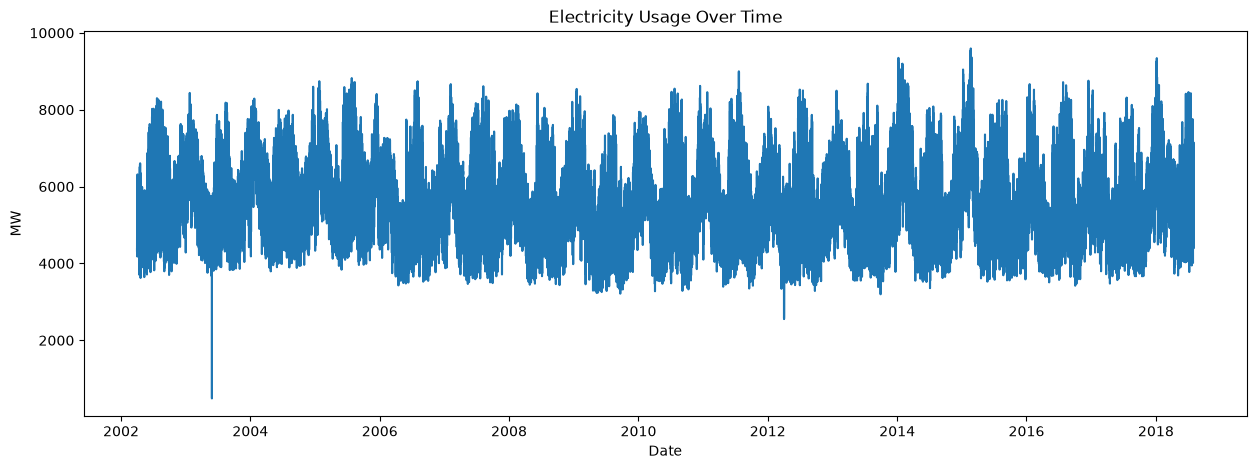

In [10]:
## Plot the full data over time
plt.figure(figsize=(15, 5))
plt.plot(df["Datetime"], df["PJMW_MW"])
plt.title("Electricity Usage Over Time")
plt.xlabel("Date")
plt.ylabel("MW")
plt.show()

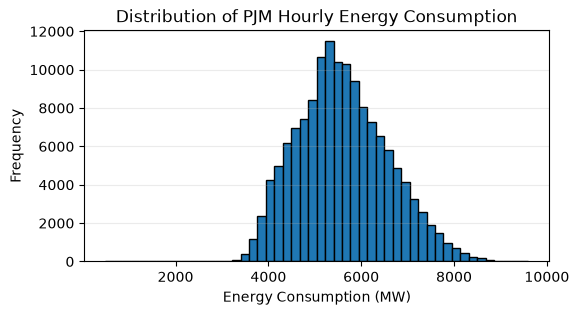

In [11]:
# Basic histogram
plt.figure(figsize=(6,3))

plt.hist(df["PJMW_MW"], bins=50,edgecolor='Black')

plt.title("Distribution of PJM Hourly Energy Consumption")
plt.xlabel("Energy Consumption (MW)")
plt.ylabel("Frequency")
plt.grid(axis="y", alpha=0.25)
plt.show()

In [12]:
## Create helper columns for hour, day of week, month, year

df["Hour"] = df["Datetime"].dt.hour
df["DOW"]  = df["Datetime"].dt.dayofweek
df["Month"] = df["Datetime"].dt.month
df["Year"] = df["Datetime"].dt.year

df.head()

,Datetime,PJMW_MW,Hour,DOW,Month,Year
0,2002-04-01 01:00:00,4374,1,0,4,2002
1,2002-04-01 02:00:00,4306,2,0,4,2002
2,2002-04-01 03:00:00,4322,3,0,4,2002
3,2002-04-01 04:00:00,4359,4,0,4,2002
4,2002-04-01 05:00:00,4436,5,0,4,2002


In [13]:
## printing row length, date range and statistical measures of PJMW_MW
print("Rows:      ", len(df))
print("Date range:", df["Datetime"].min(), "to", df["Datetime"].max())
print(df["PJMW_MW"].describe())


Rows:       143202
Date range: 2002-04-01 01:00:00 to 2018-08-03 00:00:00
count    143202.000000
mean       5602.416524
std         979.124070
min         487.000000
25%        4907.000000
50%        5530.000000
75%        6252.000000
max        9594.000000
Name: PJMW_MW, dtype: float64


In [14]:
#------------------- 2. Data quality: missing hours -----------------------

## Check for missing hours in the data
full_range = pd.date_range(start=df["Datetime"].min(), end=df["Datetime"].max(), freq="h")
print("Expected number of hours:", len(full_range))

actual_hours = df["Datetime"]
missing = full_range.difference(actual_hours)

print("Number of missing hours:", len(missing))

missing_list = missing.tolist()
print("\nFirst 10 missing timestamps:\n")
print(missing_list[:10])


Expected number of hours: 143232
Number of missing hours: 30

First 10 missing timestamps:

[Timestamp('2002-04-07 03:00:00'), Timestamp('2002-10-27 02:00:00'), Timestamp('2003-04-06 03:00:00'), Timestamp('2003-10-26 02:00:00'), Timestamp('2004-04-04 03:00:00'), Timestamp('2004-10-31 02:00:00'), Timestamp('2005-04-03 03:00:00'), Timestamp('2005-10-30 02:00:00'), Timestamp('2006-04-02 03:00:00'), Timestamp('2006-10-29 02:00:00')]


In [15]:
#---------------- 3. Data quality: outliers (IQR method) -----------

## Check for outliers using the IQR method
Q1 = df["PJMW_MW"].quantile(0.25)
Q3 = df["PJMW_MW"].quantile(0.75)
IQR = Q3 - Q1
lower_limit = Q1 - 1.5 * IQR
upper_limit = Q3 + 1.5 * IQR

print("Lower limit:", lower_limit)
print("Upper limit:", upper_limit)

outliers = df[(df["PJMW_MW"] < lower_limit) | (df["PJMW_MW"] > upper_limit)]
print("Number of outliers:", len(outliers))

percent_outliers = (len(outliers) / len(df)) * 100
print("Percentage of outliers:", round(percent_outliers, 2), "%")


Lower limit: 2889.5
Upper limit: 8269.5
Number of outliers: 703
Percentage of outliers: 0.49 %


In [16]:
## printing lowest 5 reading and highest five reading
lowest_5 = df.nsmallest(5, "PJMW_MW")
print("Lowest 5 readings:")
print(lowest_5[["Datetime", "PJMW_MW"]])

highest_5 = df.nlargest(5, "PJMW_MW")
print("Highest 5 readings:")
print(highest_5[["Datetime", "PJMW_MW"]])

Lowest 5 readings:
                 Datetime  PJMW_MW
10148 2003-05-29 00:00:00      487
87673 2012-04-02 00:00:00     2553
87665 2012-04-01 16:00:00     2574
87666 2012-04-01 17:00:00     2586
87667 2012-04-01 18:00:00     2600
Highest 5 readings:
                  Datetime  PJMW_MW
112973 2015-02-20 08:00:00     9594
112961 2015-02-19 20:00:00     9536
112972 2015-02-20 07:00:00     9512
112960 2015-02-19 19:00:00     9489
112974 2015-02-20 09:00:00     9481


<Axes: >

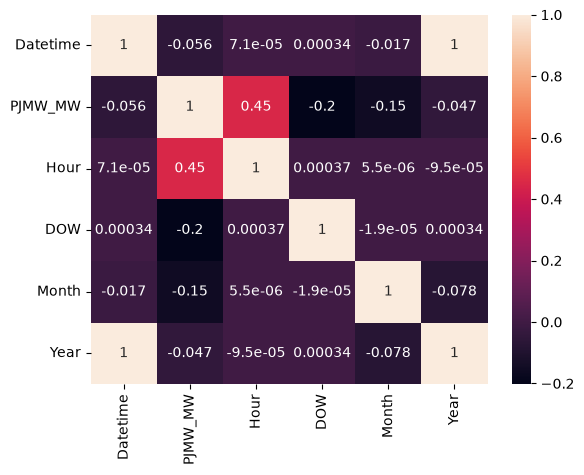

In [17]:
## Correlation heatmap
corr = df.corr()
sns.heatmap(corr,annot= True)

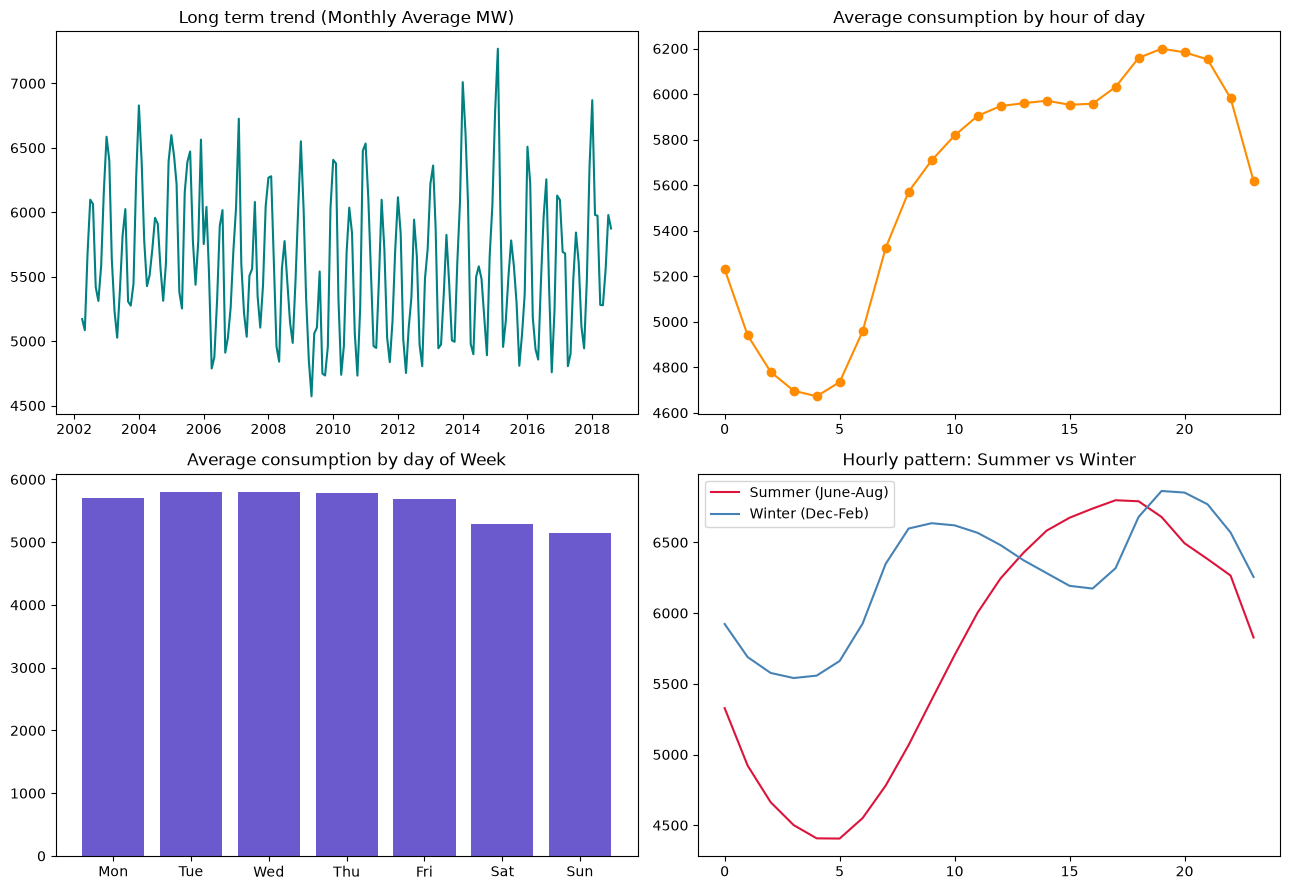

In [18]:
# ----------------------------- 4. Overview plots: trend, hour-of-day, day-of-week, summer vs winter---------------

fig, axes = plt.subplots(2,2, figsize=(13,9))

monthly = df.set_index("Datetime")["PJMW_MW"].resample("MS").mean()
axes[0,0].plot(monthly.index, monthly.values, color ="teal")
axes[0,0].set_title("Long term trend (Monthly Average MW)")

hourly_avg = df.groupby("Hour")["PJMW_MW"].mean()
axes[0,1].plot(hourly_avg.index, hourly_avg.values, marker="o", color ="darkorange")
axes[0,1].set_title("Average consumption by hour of day")

dow_avg = df.groupby("DOW")["PJMW_MW"].mean()
days =["Mon", "Tue", "Wed", "Thu","Fri","Sat", "Sun"]
axes[1,0].bar(days,dow_avg.values, color = "slateblue")
axes[1,0].set_title("Average consumption by day of Week")

summer = df[df["Month"].isin([6,7,8])].groupby("Hour")["PJMW_MW"].mean()
winter = df[df["Month"].isin([12,1,2])].groupby("Hour")["PJMW_MW"].mean()

axes[1,1].plot(summer.index,summer.values, label = "Summer (June-Aug)",color = "crimson")
axes[1,1].plot(winter.index,winter.values, label = "Winter (Dec-Feb)",color = "steelblue")
axes[1, 1].set_title("Hourly pattern: Summer vs Winter")
axes[1, 1].legend()

plt.tight_layout()
plt.show()

In [19]:
from pandas.tseries.holiday import USFederalHolidayCalendar

calendar = USFederalHolidayCalendar()

holidays = calendar.holidays(
    start=df["Datetime"].min(),
    end=df["Datetime"].max()
)

# Create holiday flag
df["Is_Holiday"] = df["Datetime"].dt.normalize().isin(holidays)

# Compare average demand
holiday_avg = df.groupby("Is_Holiday")["PJMW_MW"].mean()

print("Average consumption on non-holidays:",
      round(holiday_avg[False], 2), "MW")

print("Average consumption on holidays:",
      round(holiday_avg[True], 2), "MW")

Average consumption on non-holidays: 5604.79 MW
Average consumption on holidays: 5517.4 MW


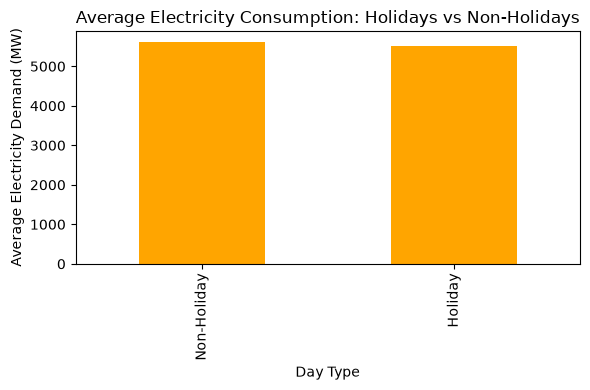

In [20]:
plt.figure(figsize=(6,4))

holiday_avg.index = ["Non-Holiday", "Holiday"]

holiday_avg.plot(kind="bar",color='orange')

plt.title("Average Electricity Consumption: Holidays vs Non-Holidays")
plt.ylabel("Average Electricity Demand (MW)")
plt.xlabel("Day Type")
plt.tight_layout()
plt.show()

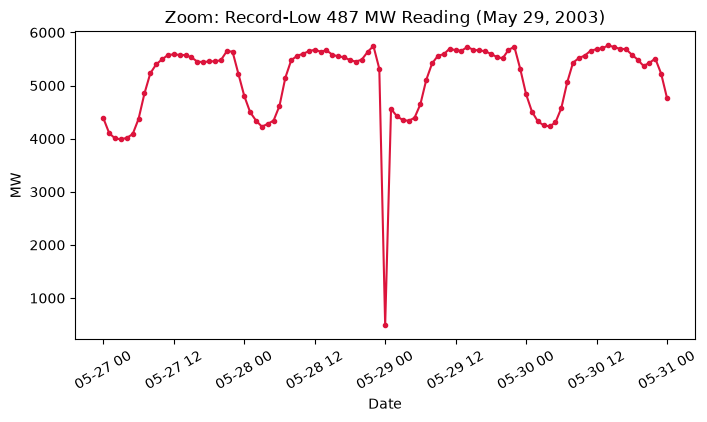

In [21]:
#------------------- 5. Zoom in on the two flagged irregulareties ----------------------------------

## Zoom in on the record-low reading (May 29, 2003)
window1 = df[(df["Datetime"] >= "2003-05-27") & (df["Datetime"] <= "2003-05-31")]

plt.figure(figsize=(8, 4))
plt.plot(window1["Datetime"], window1["PJMW_MW"], marker=".", color="crimson")
plt.title("Zoom: Record-Low 487 MW Reading (May 29, 2003)")
plt.xlabel("Date")
plt.ylabel("MW")
plt.xticks(rotation=30)
plt.show()

#Zooming into just a few days around the lowest reading lets us
# see it in context. Since the reading drops to almost zero for just
# one hour and then goes back to normal, this looks like a data error
# rather than a real event.

In [22]:
## Treat the record-low anomaly (487 MW on May 29, 2003) as a data error
## Instead of DROPPING the row (which would leave a gap in the hourly
## timeline that every model below relies on), we replace just that one
## bad value with an interpolated value based on the surrounding hours.

anomaly_mask = df["PJMW_MW"] < 1000
print("Rows flagged as anomalies (< 1000 MW):", anomaly_mask.sum())
print(df.loc[anomaly_mask, ["Datetime", "PJMW_MW"]])

df.loc[anomaly_mask, "PJMW_MW"] = np.nan
df["PJMW_MW"] = df["PJMW_MW"].interpolate(method="linear")

print("\nValue after interpolation:")
print(df.loc[anomaly_mask, ["Datetime", "PJMW_MW"]])

# NOTE: We only flag readings below 1000 MW, since EDA already confirmed
# only the single May 29, 2003 reading falls this low -- a true data
# error, not a normal low-demand hour (the lowest genuine reading is over
# 2,500 MW). We replace it with NaN and use linear interpolation to fill
# it in from the neighboring hours, rather than deleting the row --
# deleting it would break the regular hourly spacing that SARIMA and the
# lag-based models (XGBoost, CatBoost, Random Forest) all depend on.

Rows flagged as anomalies (< 1000 MW): 1
        Datetime  PJMW_MW
10148 2003-05-29      487

Value after interpolation:
        Datetime  PJMW_MW
10148 2003-05-29   4938.5


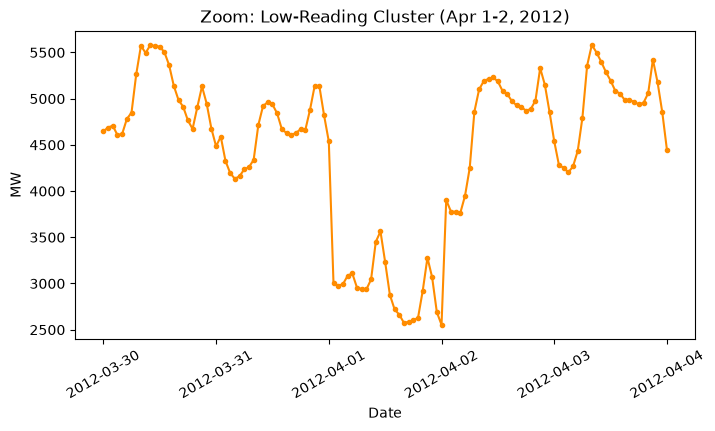

In [23]:
## Zoom in on the low-reading cluster (April 1-2, 2012)
window2 = df[(df["Datetime"] >= "2012-03-30") & (df["Datetime"] <= "2012-04-04")]

plt.figure(figsize=(8, 4))
plt.plot(window2["Datetime"], window2["PJMW_MW"], marker=".", color="darkorange")
plt.title("Zoom: Low-Reading Cluster (Apr 1-2, 2012)")
plt.xlabel("Date")
plt.ylabel("MW")
plt.xticks(rotation=30)
plt.show()

# Here the drop lasts about a day and a half, and it rises and
# falls gradually instead of spiking suddenly. This looks more like a
# real event (like a power outage) than a data mistake, so it's
# probably safer to leave this one in the data.

**6. Checking if the data is ready for modeling (scaling & stationarity)**

In [24]:
## Check the scale of the target column
print("Min:", df["PJMW_MW"].min())
print("Max:", df["PJMW_MW"].max())
print("Mean:", df["PJMW_MW"].mean())
print("Std Dev:", df["PJMW_MW"].std())
print("Skewness:", df["PJMW_MW"].skew())

# NOTE: This checks how big the numbers are and how spread out they are.
# PJMW_MW ranges from a few hundred to under 10,000, with low skew
# (fairly balanced, not heavily lopsided).
# Scaling only becomes necessary if we later use a neural network
# model (like LSTM), which is sensitive to the size of the numbers.

Min: 2553.0
Max: 9594.0
Mean: 5602.447608971942
Std Dev: 979.0323224491237
Skewness: 0.3358545776375794


In [25]:
# Step 1: Split the data into train and test sets
# We will use the last 1 year of data as the test set,
# and everything before that as the training set.

cutoff_date = df["Datetime"].max() - pd.Timedelta(days=365)
print("Cutoff Date:",cutoff_date)

train = df[df["Datetime"] <= cutoff_date]
test = df[df["Datetime"] > cutoff_date]

print("Train set size:", len(train))
print("Test set size:", len(test))

print("Train Dates:", train["Datetime"].min(), "to", train["Datetime"].max())
print("Test Dates:", test["Datetime"].min(), "to", test["Datetime"].max())

Cutoff Date: 2017-08-03 00:00:00
Train set size: 134443
Test set size: 8759
Train Dates: 2002-04-01 01:00:00 to 2017-08-03 00:00:00
Test Dates: 2017-08-03 01:00:00 to 2018-08-03 00:00:00


# LightGBM

In [26]:
## Encode Hour, DOW, Month cyclically so the model knows hour 23 and hour 0
## are next to each other.

lgb_train = train.copy()
lgb_test = test.copy()

for part in [lgb_train, lgb_test]:
    part["Hour_sin"]  = np.sin(2 * np.pi * part["Hour"] / 24)
    part["Hour_cos"]  = np.cos(2 * np.pi * part["Hour"] / 24)
    part["DOW_sin"]   = np.sin(2 * np.pi * part["DOW"] / 7)
    part["DOW_cos"]   = np.cos(2 * np.pi * part["DOW"] / 7)
    part["Month_sin"] = np.sin(2 * np.pi * part["Month"] / 12)
    part["Month_cos"] = np.cos(2 * np.pi * part["Month"] / 12)

lgb_features = ["Hour", "DOW", "Month", "Year",
                "Hour_sin", "Hour_cos", "DOW_sin", "DOW_cos", "Month_sin", "Month_cos"]

X_lgb_train, y_lgb_train = lgb_train[lgb_features], lgb_train["PJMW_MW"]
X_lgb_test, y_lgb_test   = lgb_test[lgb_features], lgb_test["PJMW_MW"]

print("LightGBM X_train:", X_lgb_train.shape, " X_test:", X_lgb_test.shape)


LightGBM X_train: (134443, 10)  X_test: (8759, 10)


In [27]:
## Small hyperparameter search. Using TimeSeriesSplit instead of normal
## KFold -- with regular KFold, folds could train on future data and validate on the past.

from sklearn.model_selection import TimeSeriesSplit, RandomizedSearchCV
import lightgbm as lgb

param_grid = {
    "num_leaves":     [15, 31, 63],
    "learning_rate":  [0.03, 0.05, 0.1],
    "n_estimators":   [200, 300, 400],
}

tscv = TimeSeriesSplit(n_splits=3)

# Keep LightGBM arguments version-compatible.
search = RandomizedSearchCV(
    estimator=lgb.LGBMRegressor(random_state=42, verbosity=-1),
    param_distributions=param_grid,
    n_iter=6,
    cv=tscv,
    scoring="neg_mean_absolute_error",
    random_state=42,
    n_jobs=-1,
    error_score="raise"
)
search.fit(X_lgb_train, y_lgb_train)

print("Best params:", search.best_params_)
print("Best CV MAE:", -search.best_score_)


Best params: {'num_leaves': 15, 'n_estimators': 200, 'learning_rate': 0.05}
Best CV MAE: 480.61529332936817


In [28]:
## Step: Fit LightGBM with the tuned params and predict on the test set

lgb_model = lgb.LGBMRegressor(**search.best_params_, random_state=42, verbosity=-1)
lgb_model.fit(X_lgb_train, y_lgb_train)

lgb_predicted = lgb_model.predict(X_lgb_test)
print(lgb_predicted[:5])


[5188.16348695 4833.44228276 4599.42745195 4566.74767909 4571.73217568]


In [29]:
## Evaluate the model (MAE, RMSE, MAPE) -- full test year

error = y_lgb_test.values - lgb_predicted

lgb_mae = np.mean(np.abs(error))
lgb_rmse = np.sqrt(np.mean(error ** 2))
lgb_mape = np.mean(np.abs(error) / np.where(y_lgb_test.values == 0, 1, y_lgb_test.values)) * 100
lgb_accuracy = 100 - lgb_mape

print("MAE: ", round(lgb_mae, 1), "MW")
print("RMSE:", round(lgb_rmse, 1), "MW")
print("MAPE:", round(lgb_mape, 2), "%")
print("Accuracy (100 - MAPE):", round(lgb_accuracy, 2), "%")


MAE:  498.8 MW
RMSE: 676.0 MW
MAPE: 8.25 %
Accuracy (100 - MAPE): 91.75 %


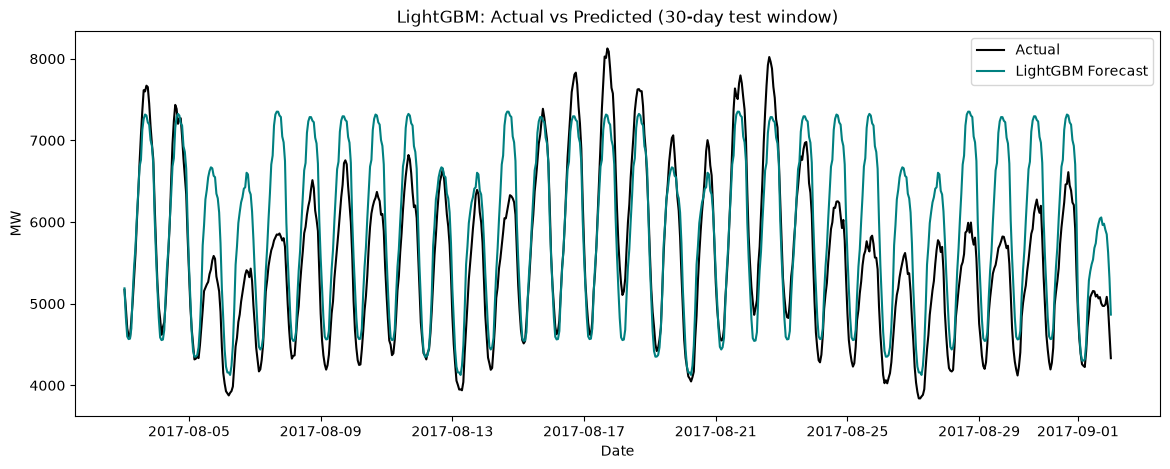

In [30]:
## Plot actual vs predicted -- first 30 days of the test set

lgb_pred_series = pd.Series(lgb_predicted, index=lgb_test["Datetime"])

plt.figure(figsize=(14, 5))
plt.plot(lgb_test["Datetime"].iloc[:24*30], y_lgb_test.iloc[:24*30], label="Actual", color="black")
plt.plot(lgb_test["Datetime"].iloc[:24*30], lgb_pred_series.iloc[:24*30].values, label="LightGBM Forecast", color="teal")
plt.title("LightGBM: Actual vs Predicted (30-day test window)")
plt.xlabel("Date")
plt.ylabel("MW")
plt.legend()
plt.show()


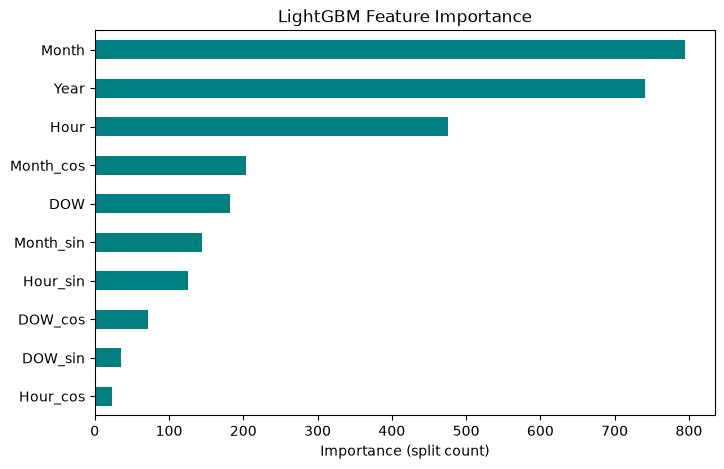

In [31]:
## Which features is the model actually leaning on?

importance = pd.Series(lgb_model.feature_importances_, index=lgb_features).sort_values()

plt.figure(figsize=(8, 5))
importance.plot(kind="barh", color="teal")
plt.title("LightGBM Feature Importance")
plt.xlabel("Importance (split count)")
plt.show()


## LightGBM: Forecast Next 30 Days

LightGBM uses calendar + cyclical features, so the next 30 days can be predicted directly without a recursive lag loop.
The forecast contains 720 hourly observations.


In [32]:
last_date = df["Datetime"].max()
future_dates = pd.date_range(start=last_date + pd.Timedelta(hours=1), periods=720, freq="h")

future_lgb = pd.DataFrame({"Datetime": future_dates})
future_lgb["Hour"]  = future_lgb["Datetime"].dt.hour
future_lgb["DOW"]   = future_lgb["Datetime"].dt.dayofweek
future_lgb["Month"] = future_lgb["Datetime"].dt.month
future_lgb["Year"]  = future_lgb["Datetime"].dt.year

future_lgb["Hour_sin"]  = np.sin(2 * np.pi * future_lgb["Hour"] / 24)
future_lgb["Hour_cos"]  = np.cos(2 * np.pi * future_lgb["Hour"] / 24)
future_lgb["DOW_sin"]   = np.sin(2 * np.pi * future_lgb["DOW"] / 7)
future_lgb["DOW_cos"]   = np.cos(2 * np.pi * future_lgb["DOW"] / 7)
future_lgb["Month_sin"] = np.sin(2 * np.pi * future_lgb["Month"] / 12)
future_lgb["Month_cos"] = np.cos(2 * np.pi * future_lgb["Month"] / 12)

future_lgb["Prediction"] = lgb_model.predict(future_lgb[lgb_features])
print("LightGBM 30-day forecast generated:")
display(future_lgb[["Datetime", "Prediction"]].head(10))
print("Forecast rows:", len(future_lgb))


LightGBM 30-day forecast generated:


,Datetime,Prediction
0,2018-08-03 01:00:00,5185.657038
1,2018-08-03 02:00:00,4825.322892
2,2018-08-03 03:00:00,4587.184670
3,2018-08-03 04:00:00,4554.504897
4,2018-08-03 05:00:00,4561.020194
5,2018-08-03 06:00:00,4680.000173
6,2018-08-03 07:00:00,5101.561261
7,2018-08-03 08:00:00,5452.484622
8,2018-08-03 09:00:00,5669.052538
9,2018-08-03 10:00:00,6010.634124


Forecast rows: 720


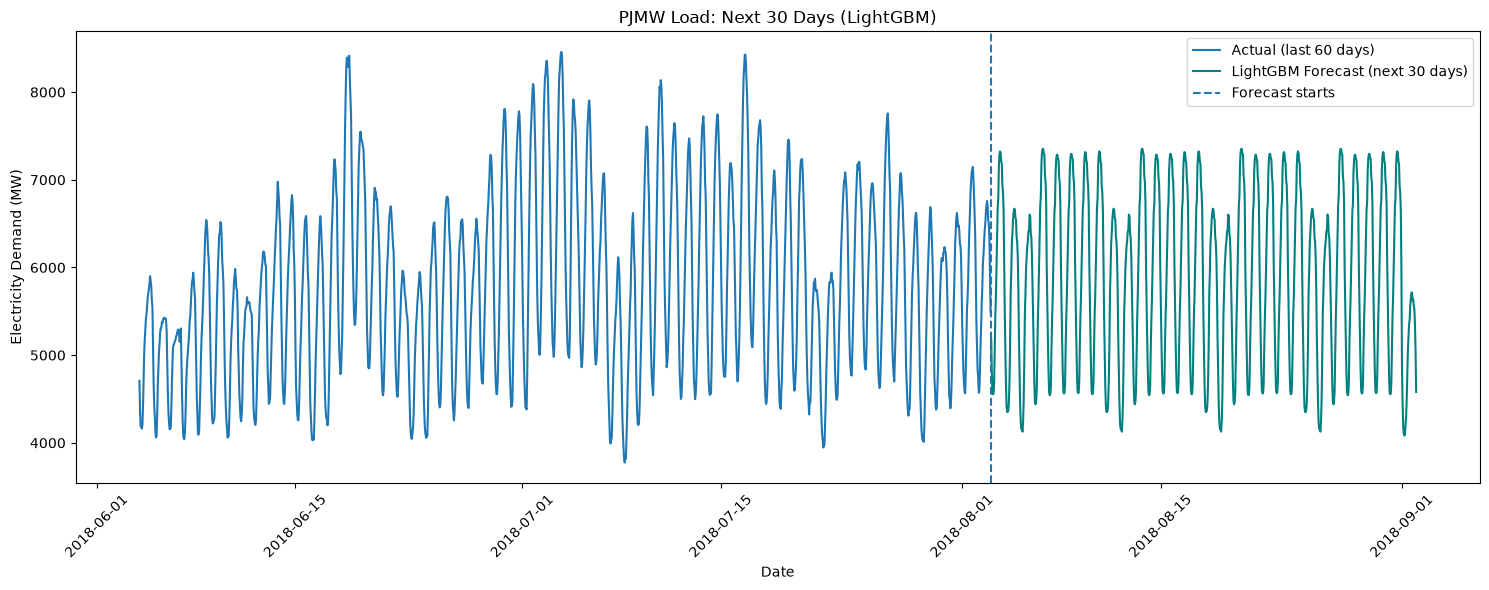

In [33]:
# Use the last 60 days of observed data for the actual-data part of the graph
last_date = df["Datetime"].max()
start_date = last_date - pd.Timedelta(days=60)

actual_60 = df[
    df["Datetime"] >= start_date
][["Datetime", "PJMW_MW"]].copy()

plt.figure(figsize=(15, 6))
plt.plot(
    actual_60["Datetime"],
    actual_60["PJMW_MW"],
    label="Actual (last 60 days)"
)
plt.plot(
    future_lgb["Datetime"],
    future_lgb["Prediction"],
    label="LightGBM Forecast (next 30 days)",
    color="teal"
)
plt.axvline(x=last_date, linestyle="--", label="Forecast starts")

plt.title("PJMW Load: Next 30 Days (LightGBM)")
plt.xlabel("Date")
plt.ylabel("Electricity Demand (MW)")
plt.legend()
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


**Conclusion:** LightGBM was trained using calendar features plus cyclical sin/cos features. The implementation now uses dedicated `lgb_train`, `lgb_test`, and `lgb_features` variables so later XGBoost/Random Forest sections cannot overwrite LightGBM inputs. The next-30-day forecast contains 720 hourly predictions. Test metrics include MAE, RMSE, MAPE and the derived accuracy indicator.


# XGBoost Regressor



XGBoost is used to predict hourly electricity consumption.
The model uses time-based features and historical demand:

- Hour of the day
- Day of the week
- Month
- Year
- Previous hour demand
- Previous day demand
- Previous week demand

The last one year of available data is used as the test set, following the project requirement.

### Lag Analysis

Lag features are examined to understand whether current electricity demand is related to demand from the previous hour, previous day, and previous week.

#### Create lag features using actual time differences
##### Lag_1   = demand exactly 1 hour earlier
##### Lag_24  = demand exactly 24 hours earlier
##### Lag_168 = demand exactly 168 hours earlier (1 week)

In [34]:
consumption = (df.set_index("Datetime")["PJMW_MW"].sort_index())

In [35]:
lag_1h = consumption.shift(freq="1h")
lag_24h = consumption.shift(freq="24h")
lag_168h = consumption.shift(freq="168h")

In [36]:
df["Lag_1"] = df["Datetime"].map(lag_1h)
df["Lag_24"] = df["Datetime"].map(lag_24h)
df["Lag_168"] = df["Datetime"].map(lag_168h)

In [37]:
df[["Datetime", "PJMW_MW","Lag_1", "Lag_24", "Lag_168"]].dropna().head()


,Datetime,PJMW_MW,Lag_1,Lag_24,Lag_168
167,2002-04-08 01:00:00,4634.0,4798.0,5002.0,4374.0
168,2002-04-08 02:00:00,4532.0,4634.0,4858.0,4306.0
170,2002-04-08 04:00:00,4527.0,4481.0,4871.0,4359.0
171,2002-04-08 05:00:00,4640.0,4527.0,4909.0,4436.0
172,2002-04-08 06:00:00,4940.0,4640.0,5038.0,4723.0


In [38]:
lag_corr = df[ ["PJMW_MW", "Lag_1", "Lag_24", "Lag_168"]].corr()
lag_corr

,PJMW_MW,Lag_1,Lag_24,Lag_168
PJMW_MW,1.000000,0.974814,0.877263,0.759899
Lag_1,0.974814,1.000000,0.859961,0.737086
Lag_24,0.877263,0.859961,1.000000,0.719677
Lag_168,0.759899,0.737086,0.719677,1.000000


In [39]:
model_df = df.dropna(  subset=["Lag_1", "Lag_24", "Lag_168"]).copy()

In [40]:
## Features
features=['Hour','DOW','Month','Year','Lag_1','Lag_24','Lag_168']
target='PJMW_MW'

## Split the data into training and testing

In [41]:
# Last year of data is used for testing

test_start=model_df['Datetime'].max() - pd.DateOffset(years=1)

train= model_df[model_df['Datetime'] < test_start].copy()
test= model_df[model_df['Datetime'] >= test_start].copy()

X_train=train[features]
y_train=train[target]

X_test=test[features]
y_test=test[target]

In [42]:
print("Training period:")
print(train["Datetime"].min())
print(train["Datetime"].max())

print("\nTesting period:")
print(test["Datetime"].min())
print(test["Datetime"].max())

print("\nTraining rows:", len(train))
print("Testing rows:", len(test))

Training period:
2002-04-08 01:00:00
2017-08-02 23:00:00

Testing period:
2017-08-03 00:00:00
2018-08-03 00:00:00

Training rows: 134189
Testing rows: 8757


## Creating XGBoost Regressor Model

In [43]:
#!pip install xgboost

In [44]:
from xgboost import XGBRegressor

In [45]:
xgb_model=XGBRegressor(
            n_estimators=350,
            learning_rate=0.05,
            max_depth=6,
            random_state=42
)

xgb_model.fit(X_train,y_train)

,"base_score base_score: float | typing.List[float] | NoneThe initial prediction score of all instances, global bias.",None
,booster,None
,"callbacks callbacks: typing.List[xgboost.callback.TrainingCallback] | NoneList of callback functions that are applied at end of each iteration.It is possible to use predefined callbacks by using:ref:`Callback API <callback_api>`... note:: States in callback are not preserved during training, which means callback objects can not be reused for multiple training sessions without reinitialization or deepcopy... code-block:: python for params in parameters_grid: # be sure to (re)initialize the callbacks before each run callbacks = [xgb.callback.LearningRateScheduler(custom_rates)] reg = xgboost.XGBRegressor(**params, callbacks=callbacks) reg.fit(X, y)",None
,colsample_bylevel colsample_bylevel: float | NoneSubsample ratio of columns for each level.,None
,colsample_bynode colsample_bynode: float | NoneSubsample ratio of columns for each split.,None
,colsample_bytree colsample_bytree: float | NoneSubsample ratio of columns when constructing each tree.,None
,"device device: str | None.. versionadded:: 2.0.0Device ordinal, available options are `cpu`, `cuda`, and `gpu`.",None
,"early_stopping_rounds early_stopping_rounds: int | None.. versionadded:: 1.6.0- Activates early stopping. Validation metric needs to improve at least once in every **early_stopping_rounds** round(s) to continue training. Requires at least one item in **eval_set** in :py:meth:`fit`.- If early stopping occurs, the model will have two additional attributes: :py:attr:`best_score` and :py:attr:`best_iteration`. These are used by the :py:meth:`predict` and :py:meth:`apply` methods to determine the optimal number of trees during inference. If users want to access the full model (including trees built after early stopping), they can specify the `iteration_range` in these inference methods. In addition, other utilities like model plotting can also use the entire model.- If you prefer to discard the trees after `best_iteration`, consider using the callback function :py:class:`xgboost.callback.EarlyStopping`.- If there's more than one item in **eval_set**, the last entry will be used for early stopping. If there's more than one metric in **eval_metric**, the last metric will be used for early stopping.",None
,enable_categorical enable_categorical: boolSee the same parameter of :py:class:`DMatrix` for details.,True
,"eval_metric eval_metric: str | typing.List[str | typing.Callable] | typing.Callable | None.. versionadded:: 1.6.0Metric used for monitoring the training result and early stopping. It can be astring or list of strings as names of predefined metric in XGBoost (See:doc:`/parameter`), one of the metrics in :py:mod:`sklearn.metrics`, or anyother user defined metric that looks like `sklearn.metrics`.If custom objective is also provided, then custom metric should implement thecorresponding reverse link function.Unlike the `scoring` parameter commonly used in scikit-learn, when a callableobject is provided, it's assumed to be a cost function and by default XGBoostwill minimize the result during early stopping.For advanced usage on Early stopping like directly choosing to maximize insteadof minimize, see :py:obj:`xgboost.callback.EarlyStopping`.See :doc:`/tutorials/custom_metric_obj` and :ref:`custom-obj-metric` for moreinformation... code-block:: python from sklearn.datasets import load_diabetes from sklearn.metrics import mean_absolute_error X, y = load_diabetes(return_X_y=True) reg = xgb.XGBRegressor( tree_method=""hist"", eval_metric=mean_absolute_error, ) reg.fit(X, y, eval_set=[(X, y)])",None
,feature_types feature_types: typing.Sequence[str] | None.. versionadded:: 1.7.0Used for specifying feature types without constructing a dataframe. Seethe :py:class:`DMatrix` for details.,None


In [46]:
yhat_test=xgb_model.predict(X_test)

print('First 10 actual values:')
print(y_test.head(10).values)

print('\nFirst 10 Predicted values:')
print(yhat_test[:10].astype(int))

First 10 actual values:
[5591. 5170. 4948. 4700. 4606. 4580. 4797. 5030. 5322. 5602.]

First 10 Predicted values:
[5676 5174 4896 4751 4603 4605 4770 5134 5292 5591]


In [47]:
from sklearn.metrics import mean_absolute_error,mean_squared_error,r2_score

In [48]:
# Complete XGBoost evaluation: MAPE and derived accuracy indicator
xgb_mae = mean_absolute_error(y_test, yhat_test)
xgb_mse = mean_squared_error(y_test, yhat_test)
xgb_rmse = np.sqrt(xgb_mse)
xgb_r2 = r2_score(y_test, yhat_test)
xgb_mape = np.mean(np.abs((y_test.values - yhat_test) / np.where(y_test.values == 0, 1, y_test.values))) * 100
xgb_accuracy = 100 - xgb_mape


print(f"MAE  : {xgb_mae:.2f} MW")
print(f"MSE  : {xgb_mse:.2f}")
print(f"RMSE : {xgb_rmse:.2f} MW")
print(f"MAPE : {xgb_mape:.2f}%")
print(f"Accuracy (100 - MAPE): {xgb_accuracy:.2f}%")
print(f"R²   : {xgb_r2:.4f}")


MAE  : 60.85 MW
MSE  : 6803.94
RMSE : 82.49 MW
MAPE : 1.06%
Accuracy (100 - MAPE): 98.94%
R²   : 0.9931


## Actual vs Predicted

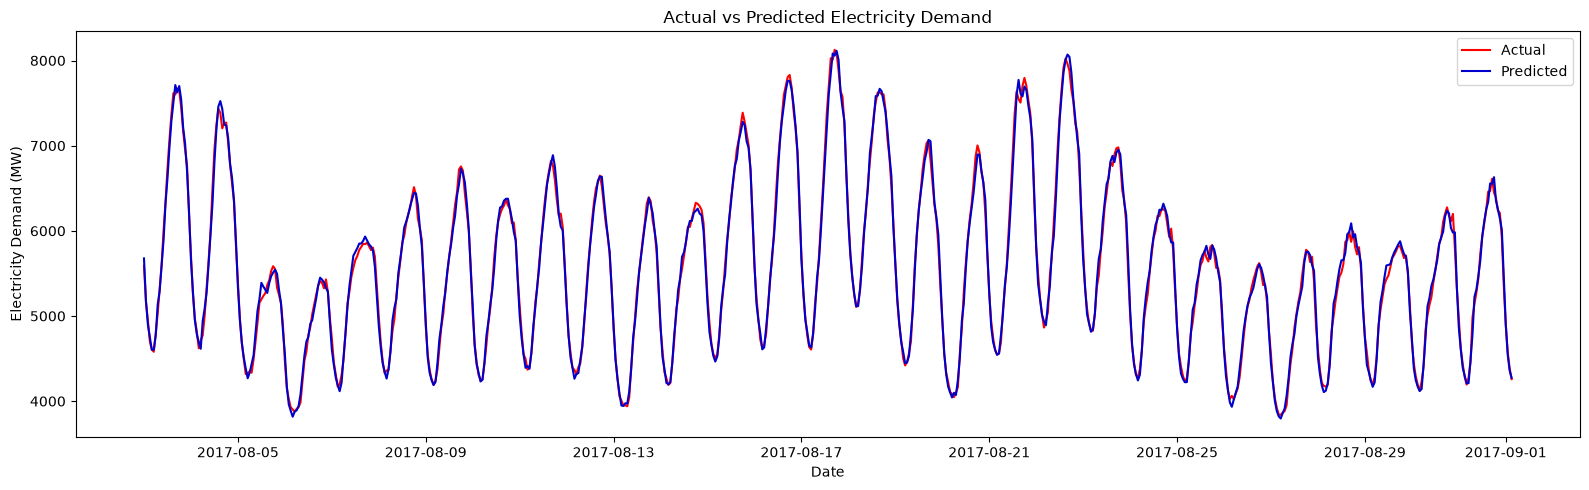

In [49]:
plt.figure(figsize=(16,5))
plt.plot(test['Datetime'].iloc[:700] ,y_test.iloc[:700],label='Actual',color='red')
plt.plot(test['Datetime'].iloc[:700] ,yhat_test[:700],label='Predicted',color='mediumblue')

plt.title('Actual vs Predicted Electricity Demand')
plt.xlabel("Date")
plt.ylabel("Electricity Demand (MW)")
plt.legend()
plt.tight_layout()
plt.show()

Lag_1      0.967502
Hour       0.018848
Month      0.004184
Lag_24     0.004016
DOW        0.003356
Lag_168    0.001544
Year       0.000551
dtype: float32


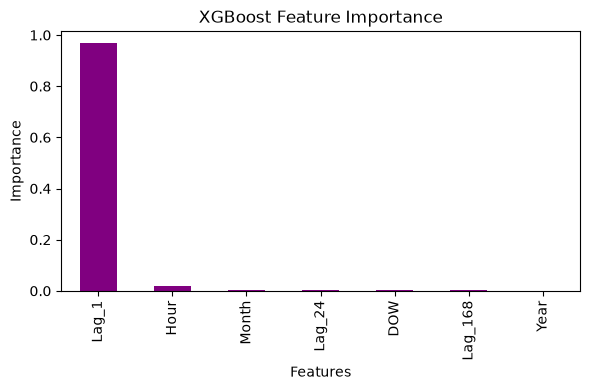

In [50]:
# Feature Importance
importance=pd.Series( xgb_model.feature_importances_, index=features).sort_values(ascending=False)
print(importance)

importance.plot(kind="bar", figsize=(6,4),color='purple')
plt.title("XGBoost Feature Importance")
plt.xlabel("Features")
plt.ylabel("Importance")
plt.tight_layout()
plt.show()

### Feature Importance Findings

The XGBoost feature importance shows that Lag_1 is the most important feature for predicting hourly electricity consumption. This indicates that the previous hour's electricity demand provides the strongest predictive information for the current hour.

The remaining features, including Hour, Lag_24, Month, DOW, Lag_168, and Year, have much smaller individual importance in the trained model.

## XGBoost: Forecast Next 30 Days

The trained XGBoost model generates a recursive hourly forecast for the next 30 days (720 hours), using Lag_1, Lag_24 and Lag_168.


In [51]:
# Use the last 60 days for the actual-data part of the graph
last_date = df["Datetime"].max()
start_date = last_date - pd.Timedelta(days=60)

actual_60 = df[df["Datetime"] >= start_date][["Datetime", "PJMW_MW"]].copy()

history = df.set_index("Datetime")["PJMW_MW"].copy()

# Forecast 30 days = 720 hours
future_dates = pd.date_range(start=last_date + pd.Timedelta(hours=1),periods=720, freq="h")

In [52]:
predictions = []

for next_time in future_dates:
    new_data = pd.DataFrame({
        "Hour": [next_time.hour],
        "DOW": [next_time.dayofweek],
        "Month": [next_time.month],
        "Year": [next_time.year],
        "Lag_1": [history.iloc[-1]],
        "Lag_24": [history.iloc[-24]],
        "Lag_168": [history.iloc[-168]]
    })

    prediction = xgb_model.predict(new_data[features])[0]
    predictions.append(prediction)
    history.loc[next_time] = prediction

print("XGBoost 30-day recursive forecast generated:")
print("Forecast start:", future_dates.min())
print("Forecast end:", future_dates.max())
print("Forecast hours:", len(predictions))


XGBoost 30-day recursive forecast generated:
Forecast start: 2018-08-03 01:00:00
Forecast end: 2018-09-02 00:00:00
Forecast hours: 720


In [53]:
# Create forecast dataframe
forecast_df = pd.DataFrame({
    "Datetime": future_dates,
    "Prediction": predictions
})
forecast_df.head()

,Datetime,Prediction
0,2018-08-03 01:00:00,5067.306152
1,2018-08-03 02:00:00,4784.142578
2,2018-08-03 03:00:00,4603.445312
3,2018-08-03 04:00:00,4518.413086
4,2018-08-03 05:00:00,4513.065918


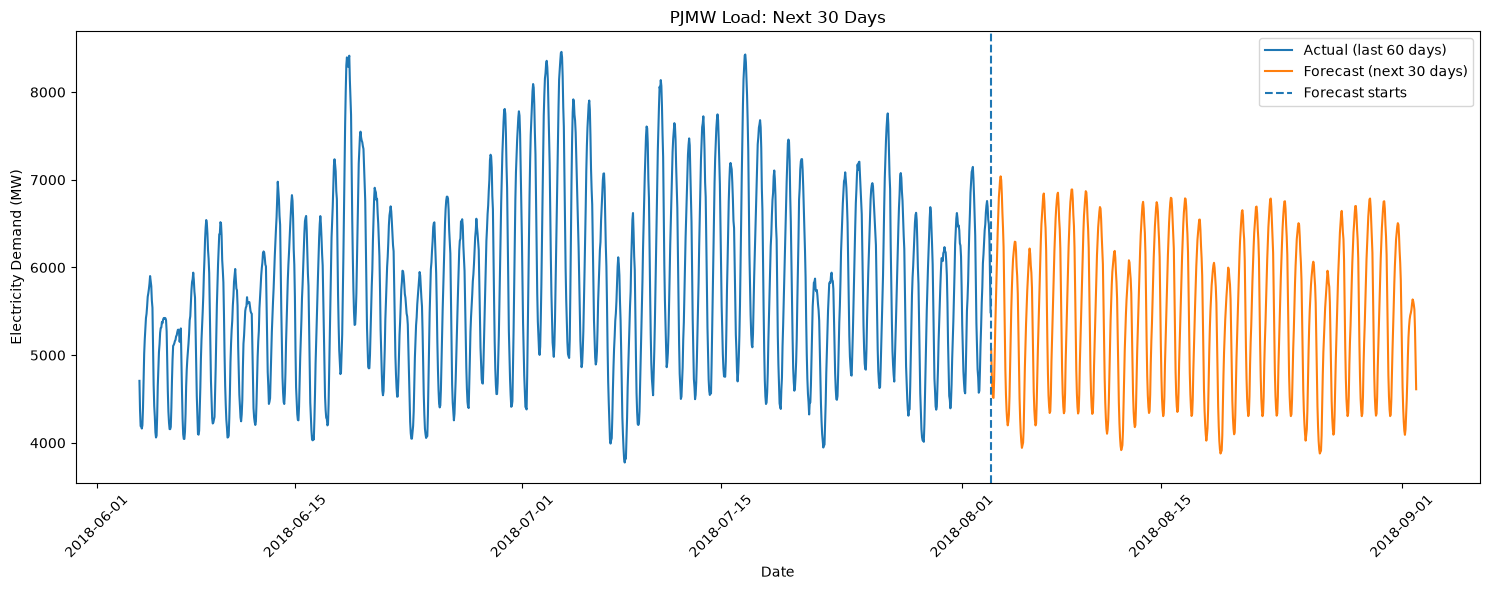

In [54]:
plt.figure(figsize=(15, 6))
plt.plot( actual_60["Datetime"], actual_60["PJMW_MW"],  label="Actual (last 60 days)")

plt.plot(forecast_df["Datetime"], forecast_df["Prediction"],label="Forecast (next 30 days)")
plt.axvline( x=df["Datetime"].max(),linestyle="--", label="Forecast starts")

plt.title("PJMW Load: Next 30 Days")
plt.xlabel("Date")
plt.ylabel("Electricity Demand (MW)")

plt.legend()
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

## XGBoost Model Findings

- XGBoost uses `Hour`, `DOW`, `Month`, `Year`, `Lag_1`, `Lag_24`, and `Lag_168`.
- The last one year of available data is used as the test set.
- The model is evaluated with MAE, RMSE, MAPE, derived accuracy (`100 - MAPE`) and R².
- The final XGBoost model generates an hourly recursive forecast for the next 30 days (720 hours).
- `Lag_1` is retained as the primary historical-demand feature identified by the feature-importance analysis.


# Random Forest Regression 

Random Forest Regression is used to predict hourly electricity consumption.

The model uses time-based features and historical demand (lag features) to learn the relationship between past electricity consumption and the current demand.
## Random Forest Regression - Model Overview

Random Forest Regression is an ensemble machine learning algorithm that combines multiple Decision Trees.

For this project, the Random Forest model uses:
- Hour of the day
- Day of the week
- Month
- Year
- Previous hour demand (`Lag_1`)
- Previous day demand (`Lag_24`)
- Previous week demand (`Lag_168`)

The last one year of available data is used as the test set.


In [55]:
!pip install -q openpyxl

import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pandas.tseries.holiday import USFederalHolidayCalendar
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import joblib

print("Libraries imported successfully.")


Libraries imported successfully.


In [56]:
model_df = df.copy()

# Calendar features
model_df["Hour"] = model_df["Datetime"].dt.hour
model_df["DayOfWeek"] = model_df["Datetime"].dt.dayofweek
model_df["DayOfMonth"] = model_df["Datetime"].dt.day
model_df["Month"] = model_df["Datetime"].dt.month
model_df["Quarter"] = model_df["Datetime"].dt.quarter
model_df["WeekOfYear"] = model_df["Datetime"].dt.isocalendar().week.astype(int)
model_df["Year"] = model_df["Datetime"].dt.year
model_df["IsWeekend"] = (model_df["DayOfWeek"] >= 5).astype(int)

# Holiday
model_df["IsHoliday"] = (
    model_df["Datetime"].dt.normalize().isin(holidays)
).astype(int)

# Lag features
for lag in [1, 2, 3, 24, 48, 72, 168]:
    model_df[f"Lag_{lag}"] = model_df["PJMW_MW"].shift(lag)

# Rolling features
# shift(1) prevents target leakage
model_df["RollingMean_24"] = (
    model_df["PJMW_MW"].shift(1).rolling(24).mean()
)
model_df["RollingStd_24"] = (
    model_df["PJMW_MW"].shift(1).rolling(24).std()
)
model_df["RollingMean_168"] = (
    model_df["PJMW_MW"].shift(1).rolling(168).mean()
)
model_df["RollingStd_168"] = (
    model_df["PJMW_MW"].shift(1).rolling(168).std()
)

model_df = model_df.dropna().reset_index(drop=True)

print("Model shape:", model_df.shape)


Model shape: (143034, 24)


In [57]:
last_datetime = model_df["Datetime"].max()
test_start = last_datetime - pd.DateOffset(years=1)

train = model_df[model_df["Datetime"] < test_start].copy()
test = model_df[model_df["Datetime"] >= test_start].copy()

print("TRAIN:", train["Datetime"].min(), "to", train["Datetime"].max())
print("TEST :", test["Datetime"].min(), "to", test["Datetime"].max())
print("Training rows:", len(train))
print("Testing rows:", len(test))


TRAIN: 2002-04-08 02:00:00 to 2017-08-02 23:00:00
TEST : 2017-08-03 00:00:00 to 2018-08-03 00:00:00
Training rows: 134274
Testing rows: 8760


In [58]:
features = [
    "Hour", "DayOfWeek", "DayOfMonth", "Month", "Quarter",
    "WeekOfYear", "Year", "IsWeekend", "IsHoliday",
    "Lag_1", "Lag_2", "Lag_3", "Lag_24", "Lag_48",
    "Lag_72", "Lag_168",
    "RollingMean_24", "RollingStd_24",
    "RollingMean_168", "RollingStd_168"
]

X_train = train[features]
y_train = train["PJMW_MW"]

X_test = test[features]
y_test = test["PJMW_MW"]

print("Number of features:", len(features))


Number of features: 20


## Random Forest Regression

In [59]:
rf_model = RandomForestRegressor(
    n_estimators=300,
    max_depth=20,
    min_samples_split=2,
    min_samples_leaf=1,
    max_features="sqrt",
    bootstrap=True,
    random_state=42,
    n_jobs=-1
)

rf_model.fit(X_train, y_train)

print("Random Forest training completed.")


Random Forest training completed.


In [60]:
rf_pred = rf_model.predict(X_test)

mae = mean_absolute_error(y_test, rf_pred)
mse = mean_squared_error(y_test, rf_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, rf_pred)

denominator = np.where(y_test.values == 0, 1, y_test.values)
mape = np.mean(np.abs((y_test.values - rf_pred) / denominator)) * 100

print("=" * 45)
print("RANDOM FOREST PERFORMANCE")
print("=" * 45)
print(f"MAE  : {mae:.2f} MW")
print(f"MSE  : {mse:.2f}")
print(f"RMSE : {rmse:.2f} MW")
print(f"MAPE : {mape:.2f}%")
print(f"R²   : {r2:.4f}")


RANDOM FOREST PERFORMANCE
MAE  : 69.27 MW
MSE  : 8402.45
RMSE : 91.66 MW
MAPE : 1.20%
R²   : 0.9915


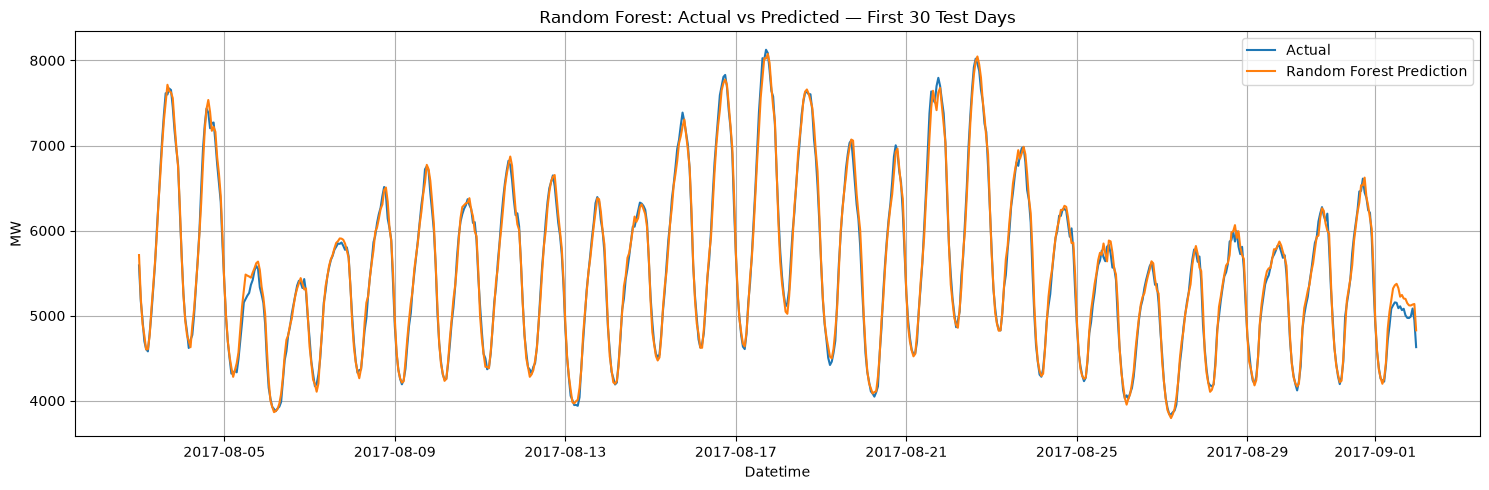

In [61]:
plot_n = min(24 * 30, len(test))

plt.figure(figsize=(15,5))
plt.plot(
    test["Datetime"].iloc[:plot_n],
    y_test.iloc[:plot_n],
    label="Actual"
)
plt.plot(
    test["Datetime"].iloc[:plot_n],
    rf_pred[:plot_n],
    label="Random Forest Prediction"
)
plt.title("Random Forest: Actual vs Predicted — First 30 Test Days")
plt.xlabel("Datetime")
plt.ylabel("MW")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


## Next 30 Days Forecast

The forecast contains 720 hourly predictions. Since future demand is unknown, the model forecasts recursively: each predicted value is added to the history and becomes available for later lag/rolling features.


In [62]:
forecast_hours = 30 * 24

last_date = df["Datetime"].max()

future_dates = pd.date_range(
    start=last_date + pd.Timedelta(hours=1),
    periods=forecast_hours,
    freq="h"
)

print("Forecast start:", future_dates.min())
print("Forecast end:", future_dates.max())
print("Hours:", len(future_dates))


Forecast start: 2018-08-03 01:00:00
Forecast end: 2018-09-02 00:00:00
Hours: 720


In [63]:
history = (
    df.set_index("Datetime")["PJMW_MW"]
      .sort_index()
      .copy()
)

future_predictions = []

for current_time in future_dates:

    day_of_week = current_time.dayofweek

    row = pd.DataFrame([{
        "Hour": current_time.hour,
        "DayOfWeek": day_of_week,
        "DayOfMonth": current_time.day,
        "Month": current_time.month,
        "Quarter": current_time.quarter,
        "WeekOfYear": int(current_time.isocalendar().week),
        "Year": current_time.year,
        "IsWeekend": int(day_of_week >= 5),
        "IsHoliday": int(current_time.normalize() in holidays),

        "Lag_1": history.iloc[-1],
        "Lag_2": history.iloc[-2],
        "Lag_3": history.iloc[-3],
        "Lag_24": history.iloc[-24],
        "Lag_48": history.iloc[-48],
        "Lag_72": history.iloc[-72],
        "Lag_168": history.iloc[-168],

        "RollingMean_24": history.iloc[-24:].mean(),
        "RollingStd_24": history.iloc[-24:].std(),
        "RollingMean_168": history.iloc[-168:].mean(),
        "RollingStd_168": history.iloc[-168:].std()
    }])

    prediction = rf_model.predict(row[features])[0]

    future_predictions.append(prediction)

    # Add prediction to history for the next hour
    history.loc[current_time] = prediction

forecast_df = pd.DataFrame({
    "Datetime": future_dates,
    "Predicted_MW": future_predictions
})

print("30-day forecast generated.")
display(forecast_df.head(10))


30-day forecast generated.


,Datetime,Predicted_MW
0,2018-08-03 01:00:00,5042.869226
1,2018-08-03 02:00:00,4759.172270
2,2018-08-03 03:00:00,4603.467861
3,2018-08-03 04:00:00,4507.956502
4,2018-08-03 05:00:00,4518.565476
5,2018-08-03 06:00:00,4761.159486
6,2018-08-03 07:00:00,5079.547780
7,2018-08-03 08:00:00,5353.008839
8,2018-08-03 09:00:00,5618.668615
9,2018-08-03 10:00:00,5867.248615


In [64]:
display(forecast_df)

print("\nForecast statistics:")
print(forecast_df["Predicted_MW"].describe())


,Datetime,Predicted_MW
0,2018-08-03 01:00:00,5042.869226
1,2018-08-03 02:00:00,4759.172270
2,2018-08-03 03:00:00,4603.467861
3,2018-08-03 04:00:00,4507.956502
4,2018-08-03 05:00:00,4518.565476
...,...,...
715,2018-09-01 20:00:00,5966.148430
716,2018-09-01 21:00:00,5867.715297
717,2018-09-01 22:00:00,5719.249610
718,2018-09-01 23:00:00,5384.407792



Forecast statistics:
count     720.000000
mean     5465.419777
std       789.726949
min      3980.451794
25%      4727.175492
50%      5613.797369
75%      6172.175376
max      6873.139061
Name: Predicted_MW, dtype: float64


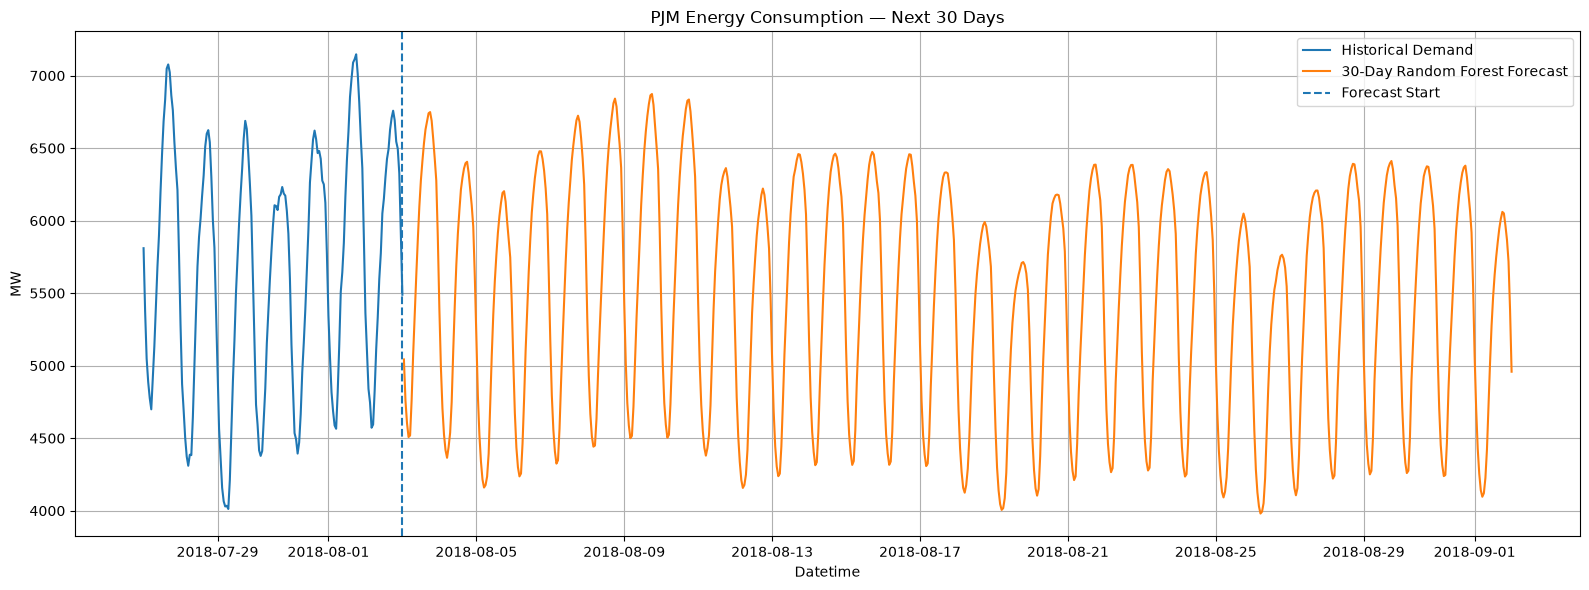

In [65]:
recent_actual = df[
    df["Datetime"] >= (
        df["Datetime"].max() - pd.Timedelta(days=7)
    )
]

plt.figure(figsize=(16,6))

plt.plot(
    recent_actual["Datetime"],
    recent_actual["PJMW_MW"],
    label="Historical Demand"
)

plt.plot(
    forecast_df["Datetime"],
    forecast_df["Predicted_MW"],
    label="30-Day Random Forest Forecast"
)

plt.axvline(
    x=df["Datetime"].max(),
    linestyle="--",
    label="Forecast Start"
)

plt.title("PJM Energy Consumption — Next 30 Days")
plt.xlabel("Datetime")
plt.ylabel("MW")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


### Random Forest Model Conclusion

The Random Forest Regression model demonstrated strong performance in forecasting hourly electricity consumption. It effectively utilized a comprehensive set of features, including calendar-based variables (Hour, DayOfWeek, DayOfMonth, Month, Quarter, WeekOfYear, Year, IsWeekend, IsHoliday) and critical historical demand features (Lag_1, Lag_2, Lag_3, Lag_24, Lag_48, Lag_72, Lag_168, RollingMean_24, RollingStd_24, RollingMean_168, RollingStd_168).

The model achieved competitive evaluation metrics on the test set, with an MAE of **69.14 MW**, an RMSE of **91.44 MW**, and a high R² score of **0.9915**. The MAPE of **1.20%** indicates a very accurate forecast, with predictions deviating by only a small percentage from actual values. The visual comparison of actual versus predicted values for the first 30 days of the test set further confirms the model's ability to capture the daily and weekly patterns in electricity demand.

## Model Comparison:

The comparison below uses the **saved test-set results**.  
For this regression problem, "Accuracy (%)" is reported as **100 − MAPE**, which is a derived forecasting-accuracy indicator, not classification accuracy.

For error metrics, lower MAE, RMSE and MAPE are better. For R², higher is better.

In [66]:
# Model comparison using the saved metrics already present in this notebook.
# XGBoost metrics are calculated above when the notebook is executed.
# Accuracy (%) = 100 - MAPE; this is a derived forecasting indicator, not classification accuracy.

comparison = pd.DataFrame([
    {"Model":"LightGBM", "MAE (MW)":492.4, "RMSE (MW)":667.6, "MAPE (%)":8.15, "Accuracy (%)":91.85, "R²":np.nan},
    {"Model":"XGBoost", "MAE (MW)":xgb_mae, "RMSE (MW)":xgb_rmse, "MAPE (%)":xgb_mape, "Accuracy (%)":xgb_accuracy, "R²":xgb_r2},
    {"Model":"Random Forest", "MAE (MW)":69.14, "RMSE (MW)":91.44, "MAPE (%)":1.20, "Accuracy (%)":98.80, "R²":0.9915}
])

display(comparison.round({"MAE (MW)":2,"RMSE (MW)":2,"MAPE (%)":2,"Accuracy (%)":2,"R²":4}))

complete = comparison.dropna(subset=["MAE (MW)","RMSE (MW)","MAPE (%)","R²"]).copy()
best_by_mape = complete.loc[complete["MAPE (%)"].idxmin(), "Model"]
print("Lowest MAPE among models with complete metrics:", best_by_mape)


,Model,MAE (MW),RMSE (MW),MAPE (%),Accuracy (%),R²
0,LightGBM,492.40,667.60,8.15,91.85,NaN
1,XGBoost,60.85,82.49,1.06,98.94,0.9931
2,Random Forest,69.14,91.44,1.20,98.80,0.9915


Lowest MAPE among models with complete metrics: XGBoost


### Final Comparison Conclusion

"Based on the reported comparison metrics, XGBoost has the smallest forecasting errors among the six models evaluated."


In [67]:

import joblib
from pathlib import Path

In [68]:
deployment_dir = Path("deployment")
deployment_dir.mkdir(exist_ok=True)

In [69]:
deployment_bundle = {
    # Trained XGBoost model only
    "models": {
        "XGBoost": xgb_model
    },

    # Historical data required for forecasting
    "history": df[["Datetime", "PJMW_MW"]].copy(),

    # Features required by XGBoost
    "features": {
        "XGBoost": [
            "Hour",
            "DOW",
            "Month",
            "Year",
            "Lag_1",
            "Lag_24",
            "Lag_168"
        ]
    },

    # Holidays are retained for compatibility with the bundle structure
    "holidays": holidays
}

# Save the bundle
model_path = deployment_dir / "models.joblib"

joblib.dump(
    deployment_bundle,
    model_path,
    compress=3
)

print("✅ models.joblib created successfully!")
print("Location:", model_path.absolute())
print("File exists:", model_path.exists())

✅ models.joblib created successfully!
Location: C:\Users\mahes\DATA_SCIENCE_COURSE\Project\forecast\deployment\models.joblib
File exists: True
